In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
text = "i love ai i love coding ai is useful coding is fun"

words = text.split()
vocab = sorted(set(words))

word_to_id = {w: i for i, w in enumerate(vocab)}
id_to_word = {i: w for w, i in word_to_id.items()}

data = torch.tensor([word_to_id[w] for w in words])

In [3]:
x = data[:-1]
y = data[1:]

In [4]:
class Transformer(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, 16)
        self.attention = nn.MultiheadAttention(
            16, 2, batch_first=True
        )
        self.fc = nn.Linear(16, vocab_size)

    def forward(self, x):
        x = self.embed(x)
        mask = torch.triu(
            torch.ones(x.size(1), x.size(1), device=x.device),
            diagonal=1
        ).bool()

        x, weights = self.attention(
            x, x, x, attn_mask=mask,
            need_weights=True, average_attn_weights=True
        )
        return self.fc(x), weights

In [5]:
model = Transformer(len(vocab))
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_history = []

for epoch in range(200):
    output, _ = model(x.unsqueeze(0))
    loss = F.cross_entropy(output.squeeze(0), y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

print("Training completed!")

Training completed!


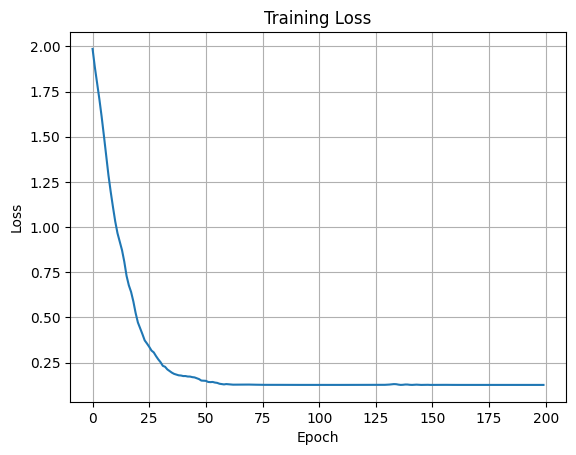

In [6]:
plt.plot(loss_history)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()
plt.show()

In [7]:
def predict(sentence):
    ids = [word_to_id[w] for w in sentence.split()]
    inputs = torch.tensor(ids).unsqueeze(0)

    with torch.no_grad():
        output, _ = model(inputs)

    next_id = output[0, -1].argmax().item()
    return id_to_word[next_id]

print("Input: i love")
print("Predicted next word:", predict("i love"))

Input: i love
Predicted next word: love


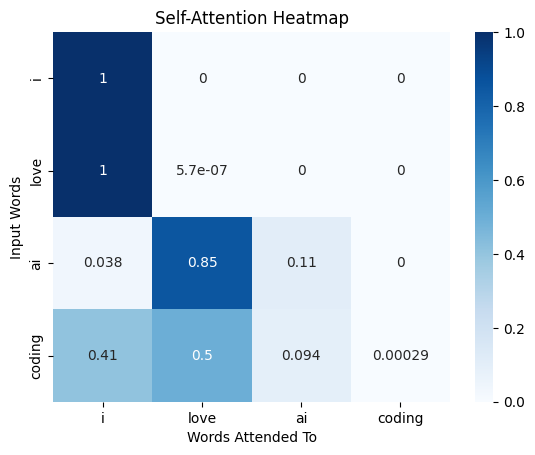

In [8]:
sentence = "i love ai coding"
ids = [word_to_id[w] for w in sentence.split()]
inputs = torch.tensor(ids).unsqueeze(0)

with torch.no_grad():
    _, weights = model(inputs)

sns.heatmap(
    weights[0].numpy(),
    xticklabels=sentence.split(),
    yticklabels=sentence.split(),
    annot=True,
    cmap="Blues"
)

plt.title("Self-Attention Heatmap")
plt.xlabel("Words Attended To")
plt.ylabel("Input Words")
plt.show()